# AA3 · Parcial II · Cuaderno 3: Transformers
**Alumno:** Emilio Frausto
**Datos:** temática opcional, mesa de ayuda de una universidad ficticia (5 clases)
**Opción:** BETO

La idea: BETO lee el mensaje de un estudiante y dice a qué área corresponde. La clase que no se puede perder es `urgencia_campus`.

### Importaciones

In [1]:
import os

os.environ["USE_TF"] = "0"  # que transformers use pytorch
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["WANDB_DISABLED"] = "true"

import random
import torch
import transformers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, recall_score, ConfusionMatrixDisplay

SEED = 42
transformers.set_seed(SEED)
pd.set_option("display.max_colwidth", 110)
GPU = torch.cuda.is_available()
print("GPU:", torch.cuda.get_device_name(0) if GPU else "no hay")

CLASES = ["inscripciones", "pagos_y_becas", "constancias", "soporte_tecnico", "urgencia_campus"]
CRITICA = "urgencia_campus"
registro = {}


def metricas(y_real, y_pred):
    return {"Exactitud": accuracy_score(y_real, y_pred),
            "F1 macro": f1_score(y_real, y_pred, average="macro"),
            "Sensibilidad urgencia": recall_score(y_real, y_pred, labels=[CRITICA], average="macro", zero_division=0)}


def registrar(nombre, pred_test, pred_val=None):
    fila = {"Exactitud (val)": accuracy_score(y_val, pred_val) if pred_val is not None else None}
    fila.update({f"{k} (prueba)": v for k, v in metricas(y_test, pred_test).items()})
    registro[nombre] = fila

GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Datos
- **Entrenamiento y validación:** mensajes hechos con plantillas y ruido, como en la práctica 5. Son 100 por clase.
- **Prueba:** 15 mensajes por clase escritos a mano y con otro estilo: faltas de ortografía, abreviaturas y dos temas a la vez.

Si un mensaje trae dos temas, lo etiqueté con el que hay que atender primero. Si hay una urgencia, gana la urgencia.

Todo es ficticio, no hay datos de personas reales.

In [2]:
# generador de mensajes con plantillas y ruido, como en la practica 5
MATERIAS = ["Cálculo II", "Física", "Programación", "Estadística", "Inglés IV", "Aprendizaje Automático III",
            "Contabilidad", "Ética", "Bases de datos", "Química"]
SEMESTRES = ["primero", "tercero", "quinto", "séptimo", "noveno", "segundo", "cuarto"]
LUGARES = ["el laboratorio", "la biblioteca", "la cafetería", "el salón 204", "el estacionamiento", "el gimnasio",
           "el edificio C", "las canchas", "el auditorio", "el pasillo del tercer piso"]
DOCUMENTOS = ["una constancia de estudios", "un kárdex", "una constancia con calificaciones", "una carta de pasante",
              "una constancia para el IMSS", "el historial académico", "una constancia de inscripción",
              "una constancia para la visa", "un certificado parcial"]
PLATAFORMAS = ["Moodle", "el portal de alumnos", "el correo institucional", "el wifi del campus", "Teams",
               "la app de la universidad", "el sistema de inscripciones en línea", "la biblioteca digital"]
FALLAS = ["dice que mi contraseña está mal", "me sale error 500", "no carga", "me bloqueó la cuenta",
          "no me llega el código de verificación", "se queda en blanco", "me dice usuario no encontrado"]
EMERGENCIAS = ["un compañero se desmayó en {lugar}", "hay humo saliendo de {lugar}", "alguien se cayó de las escaleras en {lugar} y no se mueve",
               "una alumna tiene una crisis de asma en {lugar}", "hay una fuga de gas en {lugar}",
               "un señor está amenazando a los alumnos en {lugar}", "se está incendiando un contacto en {lugar}",
               "un compañero convulsiona en {lugar}", "hay una persona sangrando mucho en {lugar}",
               "se cayó parte del techo en {lugar}"]
PAGOS = ["ya pagué la colegiatura y me sigue saliendo adeudo", "quiero saber si ya salió el resultado de la beca",
         "me cobraron recargos que no debo", "¿cuándo es la fecha límite de pago?", "no me aplicaron el descuento de beca",
         "necesito la referencia bancaria para pagar", "pagué dos veces la reinscripción", "quiero renovar mi beca",
         "¿puedo pagar la colegiatura en parcialidades?", "me retiraron la beca y no sé por qué"]

PLANTILLAS = {
    "inscripciones": ["No me deja inscribir las materias de {semestre}", "¿Cuándo abren las inscripciones de {semestre}?",
                      "Quiero dar de alta {materia}", "Necesito dar de baja {materia}", "No aparece {materia} en mi carga académica",
                      "¿Cómo me inscribo a {materia} si ya está llena?", "Me inscribí a {materia} pero no sale en mi horario",
                      "Quiero cambiarme de grupo en {materia}", "¿Puedo inscribir más materias este semestre?",
                      "No alcancé lugar en {materia}, ¿qué hago?"],
    "pagos_y_becas": ["{pago}", "Hola, {pago}", "Una duda, {pago}", "Buen día, {pago}", "{pago}, ¿me pueden ayudar?"],
    "constancias": ["Necesito {documento} para el viernes", "¿Cómo pido {documento}?", "¿Cuánto tarda {documento}?",
                    "Quiero solicitar {documento}", "¿Dónde recojo {documento}?", "Me piden {documento} en mi trabajo",
                    "¿Me pueden mandar {documento} por correo?", "¿{documento} tiene costo?"],
    "soporte_tecnico": ["No puedo entrar a {plataforma}, {falla}", "{plataforma} {falla}", "Intento entrar a {plataforma} y {falla}",
                        "¿Cómo recupero mi contraseña de {plataforma}?", "Desde ayer {plataforma} {falla}",
                        "No me deja subir la tarea a {plataforma}, {falla}"],
    "urgencia_campus": ["{emergencia}", "Ayuda, {emergencia}", "Urgente: {emergencia}", "{emergencia}, manden a alguien",
                        "Por favor, {emergencia}", "{emergencia}, ¿a quién llamo?"],
}
SALUDOS = ["", "", "", "Hola, ", "Buenas tardes, ", "Buen día, ", "Buenas, "]
CIERRES = ["", "", "", " gracias", " por favor", " porfa", ", saludos", " de antemano gracias"]


def _sin_acentos(t):
    return t.translate(str.maketrans("áéíóúÁÉÍÓÚ", "aeiouAEIOU"))


def _ruido(t, rng):
    if rng.random() < 0.35:
        t = t.lower()
    if rng.random() < 0.30:
        t = _sin_acentos(t)
    if rng.random() < 0.40:
        t = t.replace("¿", "")
    if rng.random() < 0.10 and len(t) > 12:   # cambio dos letras de lugar
        i = rng.randrange(1, len(t) - 2)
        t = t[:i] + t[i + 1] + t[i] + t[i + 2:]
    return " ".join(t.split())


def generar(n_por_clase=100, semilla=42):
    rng = random.Random(semilla)
    datos = []
    for clase in CLASES:
        vistos = set()
        while len(vistos) < n_por_clase:
            texto = rng.choice(PLANTILLAS[clase]).format(
                semestre=rng.choice(SEMESTRES), materia=rng.choice(MATERIAS), documento=rng.choice(DOCUMENTOS),
                plataforma=rng.choice(PLATAFORMAS), falla=rng.choice(FALLAS), pago=rng.choice(PAGOS),
                emergencia=rng.choice(EMERGENCIAS).format(lugar=rng.choice(LUGARES)))
            texto = texto[0].upper() + texto[1:]
            texto = _ruido(rng.choice(SALUDOS) + texto + rng.choice(CIERRES), rng)
            if texto not in vistos:
                vistos.add(texto)
                datos.append((texto, clase))
    rng.shuffle(datos)
    return datos

datos = generar(n_por_clase=100, semilla=SEED)
print(f"Sintéticos: {len(datos)} mensajes ({len(datos) // len(CLASES)} por clase)")

Sintéticos: 500 mensajes (100 por clase)


In [3]:
# prueba escrita a mano, con otro estilo y sin usar el generador
PRUEBA = [
    # inscripciones (15)
    ("oigan el sistema me dice q ya no ay cupo en estadistica y la necesito pa no atrasarme", "inscripciones"),
    ("Soy de 5to y me salió el horario sin la optativa que elegí, me la pueden meter?", "inscripciones"),
    ("como le hago para meter una materia de otra carrera como optativa", "inscripciones"),
    ("Reprobé cálculo, ¿la puedo volver a cursar este semestre o espero al otro?", "inscripciones"),
    ("me dieron de baja todas mis materias sin avisarme!!! que pasó??", "inscripciones"),
    ("Buenas, ¿a qué hora es mi turno para escoger grupos?", "inscripciones"),
    ("Quiero cambiarme de turno matutino al vespertino", "inscripciones"),
    ("ya pagué la reinscripción pero sigo sin poder elegir materias", "inscripciones"),
    ("mi carga dice 0 créditos y ya estaba inscrito desde la semana pasada", "inscripciones"),
    ("¿Hay algún límite de materias que puedo llevar si soy irregular?", "inscripciones"),
    ("Me equivoqué y metí Física II en vez de Física I, ¿lo pueden corregir?", "inscripciones"),
    ("Mi tutor me dijo que pida alta extemporánea, ¿con quién voy?", "inscripciones"),
    ("vengo de intercambio y no se como registrar mis clases aqui", "inscripciones"),
    ("¿Se puede llevar el servicio social al mismo tiempo que 8 materias? quiero inscribir todas", "inscripciones"),
    ("no me aparece el botón de inscribir en el portal, ya tiene 3 días así", "inscripciones"),
    # pagos_y_becas (15)
    ("me llegó un correo diciendo que debo 4 mil pesos pero yo ya lo liquidé en agosto", "pagos_y_becas"),
    ("Mi papá hizo la transferencia el lunes y todavía no se refleja", "pagos_y_becas"),
    ("¿la beca deportiva cubre la inscripción o solo las mensualidades?", "pagos_y_becas"),
    ("Saqué 8.9 de promedio, ¿pierdo la beca de excelencia?", "pagos_y_becas"),
    ("necesito factura del pago de este mes a nombre de mi mamá", "pagos_y_becas"),
    ("me pueden dar prórroga? este mes no completo la colegiatura", "pagos_y_becas"),
    ("¿Dónde veo cuánto debo? No encuentro mi estado de cuenta", "pagos_y_becas"),
    ("Me cobraron la credencial dos veces en la misma tarjeta", "pagos_y_becas"),
    ("hola quisiera aplicar a la beca socioeconomica, que papeles ocupo", "pagos_y_becas"),
    ("¿Aceptan pago con tarjeta de crédito a meses?", "pagos_y_becas"),
    ("me bloquearon el portal por adeudo pero ya pagué, ¿cuándo lo liberan?", "pagos_y_becas"),
    ("El banco me rechazó la referencia, ¿me generan otra?", "pagos_y_becas"),
    ("¿Si me doy de baja temporal me devuelven lo de la colegiatura?", "pagos_y_becas"),
    ("Ya salieron los resultados del apoyo de transporte?", "pagos_y_becas"),
    ("necesito comprobante de que tengo beca para un trámite del gobierno", "pagos_y_becas"),
    # constancias (15)
    ("Ocupo papel que diga que soy alumno regular pal seguro de mi papá", "constancias"),
    ("me urge mi kardex sellado para una entrevista de prácticas el lunes", "constancias"),
    ("¿la constancia digital tiene validez o la necesito en físico?", "constancias"),
    ("Pedí una constancia hace 2 semanas y no me ha llegado nada", "constancias"),
    ("¿pueden poner mi promedio en la constancia? me lo pide la empresa", "constancias"),
    ("necesito una carta en inglés que diga que estudio aquí, es para el consulado", "constancias"),
    ("Mi constancia salió con mi nombre mal escrito, ¿me la corrigen?", "constancias"),
    ("¿Puede recoger mi constancia otra persona? estoy fuera de la ciudad", "constancias"),
    ("buen día, necesito un documento oficial con las materias que he cursado", "constancias"),
    ("¿Cuántos días hábiles tarda el certificado parcial?", "constancias"),
    ("Para el transporte público me piden comprobante de estudios vigente", "constancias"),
    ("me falta la constancia de servicio social liberado, ¿dónde la tramito?", "constancias"),
    ("se me perdió mi credencial y necesito algo que compruebe que soy estudiante", "constancias"),
    ("La constancia para la visa necesita firma del director, ¿se puede?", "constancias"),
    ("Quiero un historial académico, ya pagué el trámite y la constancia de pago tmb la traigo", "constancias"),
    # soporte_tecnico (15)
    ("el moodle no me deja entregar y la tarea vence en 1 hora!!", "soporte_tecnico"),
    ("No me llega el correo para restablecer contraseña, ya revisé spam", "soporte_tecnico"),
    ("en la biblioteca digital me sale acceso denegado aunque ya inicie sesion", "soporte_tecnico"),
    ("El internet del edificio B no sirve desde la mañana", "soporte_tecnico"),
    ("¿Cómo instalo Office con mi cuenta de la uni? me pide licencia", "soporte_tecnico"),
    ("la app se cierra sola cada que la abro, tengo android", "soporte_tecnico"),
    ("No puedo ver mis calificaciones en el portal, sale una pantalla gris", "soporte_tecnico"),
    ("Teams no me deja entrar a la clase en línea, dice que no tengo permiso", "soporte_tecnico"),
    ("me hackearon el correo institucional y están mandando spam", "soporte_tecnico"),
    ("Las computadoras del laboratorio no prenden, el profe ya llegó y no podemos empezar", "soporte_tecnico"),
    ("cambié de celular y perdí la verificación en dos pasos", "soporte_tecnico"),
    ("No puedo pagar en línea porque el portal se traba al poner la tarjeta", "soporte_tecnico"),
    ("el proyector del aula 12 no detecta la laptop", "soporte_tecnico"),
    ("quiero inscribir materias pero el sistema me saca a cada rato, ya probé en otra compu", "soporte_tecnico"),
    ("se borró mi entrega de moodle y el profe dice que no la ve", "soporte_tecnico"),
    # urgencia_campus (15)
    ("Mi amiga se puso muy mal en el baño del edificio A, está pálida y no responde", "urgencia_campus"),
    ("Hay un olor muy fuerte a gas en el laboratorio de química, nos salimos todos", "urgencia_campus"),
    ("un chavo se cayó de la bici en el estacionamiento y se pegó en la cabeza, sangra", "urgencia_campus"),
    ("Está temblando y se agrietó la pared del salón, ¿evacuamos?", "urgencia_campus"),
    ("hay un hombre armado afuera de la puerta 3", "urgencia_campus"),
    ("Mi compañero es alérgico y lo picó una abeja, se le está hinchando la cara", "urgencia_campus"),
    ("No puedo entrar a Moodle porque estamos encerrados, hay un incendio en el pasillo", "urgencia_campus"),
    ("necesito una constancia pero ahorita lo urgente es que un compañero se desmayó en la fila de servicios escolares", "urgencia_campus"),
    ("se rompió un tubo y hay agua cayendo en los contactos del laboratorio de cómputo, saltan chispas", "urgencia_campus"),
    ("Una alumna dice que alguien la está siguiendo dentro del campus y tiene miedo", "urgencia_campus"),
    ("en la cafetería un señor se está ahogando con comida", "urgencia_campus"),
    ("Mi compañera está teniendo un ataque de pánico muy fuerte y no puede respirar", "urgencia_campus"),
    ("Se metieron a robar al edificio D, hay alumnos encerrados en un salón", "urgencia_campus"),
    ("chocaron dos carros en el estacionamiento y hay un herido", "urgencia_campus"),
    ("ya pagué la colegiatura pero eso no importa ahorita, un maestro se desplomó en clase", "urgencia_campus"),
]
print(f"Prueba escrita aparte: {len(PRUEBA)} mensajes ({len(PRUEBA) // len(CLASES)} por clase)")

Prueba escrita aparte: 75 mensajes (15 por clase)


In [4]:
from sklearn.model_selection import train_test_split

textos = [t for t, _ in datos]
etiquetas = [c for _, c in datos]
x_train, x_val, y_train, y_val = train_test_split(textos, etiquetas, test_size=0.2, stratify=etiquetas, random_state=SEED)
x_test = [t for t, _ in PRUEBA]
y_test = [c for _, c in PRUEBA]

print(f"Entrenamiento: {len(x_train)} · Validacion: {len(x_val)} · Prueba: {len(x_test)}")
pd.Series(y_train).value_counts().rename("entrenamiento").to_frame().join(pd.Series(y_test).value_counts().rename("prueba"))

Entrenamiento: 400 · Validacion: 100 · Prueba: 75


,entrenamiento,prueba
soporte_tecnico,80,15
pagos_y_becas,80,15
constancias,80,15
urgencia_campus,80,15
inscripciones,80,15


## 2. Línea base
Uso dos líneas base, igual que en la práctica 5:
1. **Bigramas:** TF-IDF con regresión logística.
2. **Zero-shot:** mDeBERTa sin entrenar, por eso solo lo mido en la prueba.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

bigramas = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True), LogisticRegression(max_iter=2000, C=10))
bigramas.fit(x_train, y_train)
pred_val_big, pred_test_big = bigramas.predict(x_val), bigramas.predict(x_test)
registrar("Bigramas", pred_test_big, pred_val_big)
print(metricas(y_test, pred_test_big))

{'Exactitud': 0.7066666666666667, 'F1 macro': 0.7064853577794754, 'Sensibilidad urgencia': 0.8666666666666667}


In [6]:
from transformers import pipeline

DESCRIPCIONES = {"inscripciones": "inscripción, altas, bajas o cambios de materias y grupos",
                 "pagos_y_becas": "pagos, colegiaturas, adeudos o becas",
                 "constancias": "solicitar una constancia, kárdex o documento oficial",
                 "soporte_tecnico": "un problema técnico con una plataforma, cuenta o equipo",
                 "urgencia_campus": "una emergencia de salud o seguridad en el campus"}
a_clase = {v: k for k, v in DESCRIPCIONES.items()}

zero_shot = pipeline("zero-shot-classification", model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli", device=0 if GPU else -1)
salidas = zero_shot(x_test, candidate_labels=list(DESCRIPCIONES.values()), hypothesis_template="Este mensaje trata de {}.")
pred_test_zs = [a_clase[s["labels"][0]] for s in salidas]
registrar("Zero-shot", pred_test_zs)
print(metricas(y_test, pred_test_zs))

# libero la gpu para BETO
del zero_shot
if GPU:
    torch.cuda.empty_cache()

W1106 11:35:12.556000 27220 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

{'Exactitud': 0.3333333333333333, 'F1 macro': 0.22142857142857145, 'Sensibilidad urgencia': 0.0}


## 3. Modelo
BETO con una capa nueva que saca las 5 clases. Lo ajusté completo con el `Trainer`, con los mismos valores de la práctica: learning rate de 3e-5, 4 épocas y lotes de 16.

In [7]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding

NOMBRE_BETO = "dccuchile/bert-base-spanish-wwm-cased"
id2label = dict(enumerate(CLASES))
label2id = {v: k for k, v in id2label.items()}
tokenizador = AutoTokenizer.from_pretrained(NOMBRE_BETO)
modelo = AutoModelForSequenceClassification.from_pretrained(NOMBRE_BETO, revision="refs/pr/3", num_labels=len(CLASES),
                                                            id2label=id2label, label2id=label2id)
print("Tokens de un mensaje:", tokenizador.tokenize(x_train[0]))


class DatasetMensajes(torch.utils.data.Dataset):
    def __init__(self, textos, etiquetas):
        self.codificados = tokenizador(textos, truncation=True, max_length=64)
        self.etiquetas = [label2id[e] for e in etiquetas]
    def __len__(self):
        return len(self.etiquetas)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.codificados.items()}
        item["labels"] = self.etiquetas[i]
        return item

ds_train, ds_val, ds_test = DatasetMensajes(x_train, y_train), DatasetMensajes(x_val, y_val), DatasetMensajes(x_test, y_test)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Tokens de un mensaje: ['Buenas', ',', 'No', 'puedo', 'entrar', 'a', 'el', 'portal', 'de', 'alumnos', ',', 'no', 'me', 'llega', 'el', 'codi', '##go', 'de', 'verific', '##acion', 'por', 'favor']


In [8]:
from transformers import Trainer, TrainingArguments

def calcular_metricas(eval_pred):
    logits, etiquetas_num = eval_pred
    pred = logits.argmax(axis=-1)
    return {"accuracy": accuracy_score(etiquetas_num, pred), "f1_macro": f1_score(etiquetas_num, pred, average="macro")}

args = TrainingArguments(output_dir="modelos/beto", num_train_epochs=4, learning_rate=3e-5,
                         per_device_train_batch_size=16, per_device_eval_batch_size=64, weight_decay=0.01,
                         eval_strategy="epoch", save_strategy="no", logging_strategy="epoch",
                         fp16=GPU and torch.cuda.get_device_capability()[0] >= 7, report_to="none", seed=SEED)
trainer = Trainer(model=modelo, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                  data_collator=DataCollatorWithPadding(tokenizador), compute_metrics=calcular_metricas)
trainer.train()

def predecir(ds):
    return [id2label[i] for i in trainer.predict(ds).predictions.argmax(axis=-1)]

pred_val_beto, pred_test_beto = predecir(ds_val), predecir(ds_test)
registrar("BETO ajustado", pred_test_beto, pred_val_beto)

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.170843,0.451360,0.970000,0.969830
2,0.193190,0.026715,1.000000,1.000000
3,0.019519,0.009072,1.000000,1.000000
4,0.010970,0.007703,1.000000,1.000000


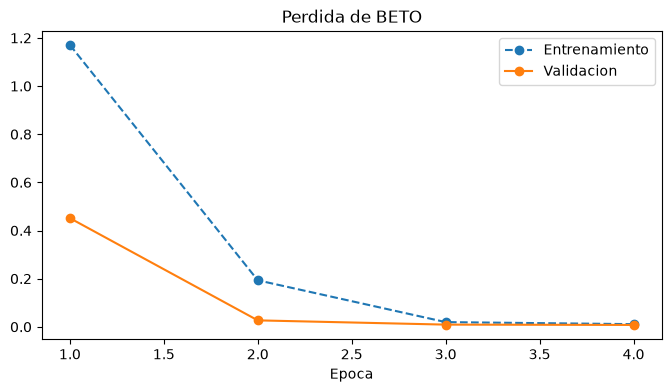

In [9]:
hist = pd.DataFrame(trainer.state.log_history)
perdida_train = hist.dropna(subset=["loss"])
perdida_val = hist.dropna(subset=["eval_loss"])

plt.figure(figsize=(8, 4))
plt.plot(perdida_train["epoch"], perdida_train["loss"], "o--", label="Entrenamiento")
plt.plot(perdida_val["epoch"], perdida_val["eval_loss"], "o-", label="Validacion")
plt.title("Perdida de BETO")
plt.xlabel("Epoca")
plt.legend()
plt.show()

## 4. Resultados
Las mismas métricas de prueba para los tres modelos. La exactitud de validación solo es de referencia, porque esos mensajes salen de las mismas plantillas que el entrenamiento.

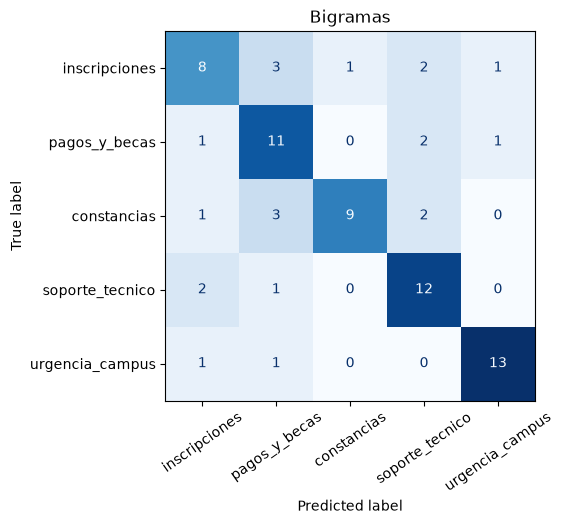

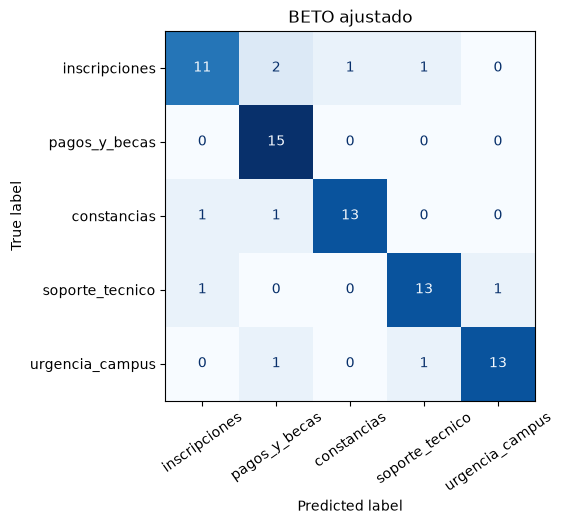

In [10]:
for pred, titulo in [(pred_test_big, "Bigramas"), (pred_test_beto, "BETO ajustado")]:
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=CLASES, xticks_rotation=35, cmap="Blues", colorbar=False)
    plt.title(titulo)
    plt.show()

In [11]:
resultados = pd.DataFrame(registro).T
resultados.astype(float).round(3)

,Exactitud (val),Exactitud (prueba),F1 macro (prueba),Sensibilidad urgencia (prueba)
Bigramas,1.0,0.707,0.706,0.867
Zero-shot,NaN,0.333,0.221,0.000
BETO ajustado,1.0,0.867,0.866,0.867


## 5. Conclusión
### Errores de los modelos

In [12]:
errores = pd.DataFrame({"Mensaje": x_test, "Real": y_test, "Bigramas": pred_test_big,
                        "Zero-shot": pred_test_zs, "BETO": pred_test_beto})
errores = errores[(errores["BETO"] != errores["Real"]) | (errores["Bigramas"] != errores["Real"])]
print("Mensajes donde falla BETO o los bigramas:", len(errores))
errores

Mensajes donde falla BETO o los bigramas: 26


,Mensaje,Real,Bigramas,Zero-shot,BETO
0,oigan el sistema me dice q ya no ay cupo en estadistica y la necesito pa no atrasarme,inscripciones,soporte_tecnico,constancias,pagos_y_becas
1,"Soy de 5to y me salió el horario sin la optativa que elegí, me la pueden meter?",inscripciones,pagos_y_becas,inscripciones,inscripciones
2,como le hago para meter una materia de otra carrera como optativa,inscripciones,constancias,inscripciones,inscripciones
5,"Buenas, ¿a qué hora es mi turno para escoger grupos?",inscripciones,pagos_y_becas,constancias,inscripciones
7,ya pagué la reinscripción pero sigo sin poder elegir materias,inscripciones,pagos_y_becas,constancias,pagos_y_becas
8,mi carga dice 0 créditos y ya estaba inscrito desde la semana pasada,inscripciones,soporte_tecnico,inscripciones,inscripciones
11,"Mi tutor me dijo que pida alta extemporánea, ¿con quién voy?",inscripciones,inscripciones,constancias,constancias
12,vengo de intercambio y no se como registrar mis clases aqui,inscripciones,urgencia_campus,inscripciones,inscripciones
14,"no me aparece el botón de inscribir en el portal, ya tiene 3 días así",inscripciones,inscripciones,soporte_tecnico,soporte_tecnico
16,Mi papá hizo la transferencia el lunes y todavía no se refleja,pagos_y_becas,soporte_tecnico,inscripciones,pagos_y_becas


### Umbral para `urgencia_campus`
Marco urgencia si su probabilidad pasa el umbral, aunque no sea la clase más probable.

In [13]:
entrada = tokenizador(x_test, truncation=True, max_length=64, padding=True, return_tensors="pt").to(trainer.model.device)
with torch.no_grad():
    probs_test = torch.softmax(trainer.model(**entrada).logits, dim=-1).cpu().numpy()
i_urg = label2id[CRITICA]

filas = []
for umbral in [0.5, 0.3, 0.2, 0.1, 0.05]:
    pred = [CRITICA if p[i_urg] >= umbral else id2label[int(p.argmax())] for p in probs_test]
    m = metricas(y_test, pred)
    falsas = sum(1 for r, p in zip(y_test, pred) if p == CRITICA and r != CRITICA)
    filas.append({"Umbral": umbral, "Sensibilidad urgencia": round(m["Sensibilidad urgencia"], 3),
                  "Falsas alarmas": falsas, "Exactitud": round(m["Exactitud"], 3)})
display(pd.DataFrame(filas))

# las urgencias reales con menor probabilidad
urgencias = pd.DataFrame({"Mensaje": x_test, "Real": y_test, "P(urgencia)": probs_test[:, i_urg].round(3)})
urgencias[urgencias["Real"] == CRITICA].sort_values("P(urgencia)").head(5)

,Umbral,Sensibilidad urgencia,Falsas alarmas,Exactitud
0,0.50,0.867,1,0.867
1,0.30,0.867,1,0.867
2,0.20,0.867,1,0.867
3,0.10,0.933,1,0.880
4,0.05,0.933,2,0.867


,Mensaje,Real,P(urgencia)
74,"ya pagué la colegiatura pero eso no importa ahorita, un maestro se desplomó en clase",urgencia_campus,0.027
66,"No puedo entrar a Moodle porque estamos encerrados, hay un incendio en el pasillo",urgencia_campus,0.167
71,Mi compañera está teniendo un ataque de pánico muy fuerte y no puede respirar,urgencia_campus,0.981
65,"Mi compañero es alérgico y lo picó una abeja, se le está hinchando la cara",urgencia_campus,0.985
67,necesito una constancia pero ahorita lo urgente es que un compañero se desmayó en la fila de servicios esc...,urgencia_campus,0.985


**Análisis** 

- **Comparación:** BETO 0.867 de exactitud y 0.866 de F1 macro en prueba, contra 0.707 (bigramas) y 0.333 (zero-shot). En validación todos rondan el 100 %: la prueba escrita aparte es la que dice la verdad.
- **Errores de BETO:** Fallo en 10 y bigramas en 22. Algo que me parece curioso, es que BETO le pone mucha importancia a ciertas palabras que a la hora de hacer su prediccion, se basa mas en esas partes. Como en este ejemplo, que es de constancia pero BETO predijo que eran pagos y becas 
    - Ejemplo: "Quiero un historial académico, ya pagué el trámite y la constancia de pago tmb la traigo"
    
- **Umbral elegido:  0.10.** Con 0.5 BETO pierde 2 de las 15 urgencias. Con 0.10 recupera la del incendio ("No puedo entrar a Moodle porque estamos encerrados, hay un incendio en el pasillo"), la sensibilidad sube de 87 % a 93 % y sigue habiendo 1 sola falsa alarma. Con 0.05 no se gana nada y sube a 2 falsas alarmas, por eso me quedo con 0.10. Prefiero una falsa alarma a perder una urgencia, porque una falsa alarma solo hace que alguien revise el mensaje.